# FFT reconstruction: isolated ablation

Three variants of the **current DecoVAEFM**, differing only in the final conversion
of predicted complex coefficients into a seasonal curve:

1. `original`: the current FFT bin remapping and `irfft(T+H)`.
2. `amplitude`: the same remapping, with coefficients multiplied by `(T+H)/T`.
3. `exact_frequency`: the same coefficients evaluated directly at frequencies `k/T`;
   scale `1/T`, weight 1 for DC/Nyquist and 2 for all other frequencies.

The encoders, input decomposition, heads, parameter count, and loss are identical.
No precomputed seasonal components or period estimates were added. The main package code was unchanged.

Exact `k/T` preserves the original FFT frequencies but **does not estimate true non-integer periods**:
the extension remains T-periodic. All components are measured in linearly normalized
coordinates. NRMSE is expressed in units of the standard deviation of the *full series context*.
In the identity check, the unit is the standard deviation of the true seasonal component in the corresponding segment.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

cwd = Path.cwd().resolve()
candidates = [p for parent in (cwd, *cwd.parents)
              for p in (parent, parent / 'experiments' / 'decomposition')]
EXP = next(p for p in candidates if (p / 'results' / 'fft_reconstruction_summary.csv').exists())
R = EXP / 'results'
summary = pd.read_csv(R / 'fft_reconstruction_summary.csv')
by_seed = pd.read_csv(R / 'fft_reconstruction_by_seed.csv')
paired = pd.read_csv(R / 'fft_reconstruction_paired.csv')
identity = pd.read_csv(R / 'fft_reconstruction_identity.csv')
runs = pd.read_csv(R / 'fft_reconstruction_runs.csv')
topk = pd.read_csv(R / 'fft_reconstruction_topk.csv')
variants = ['original', 'amplitude', 'exact_frequency']
colors = dict(zip(variants, ['#64748b', '#f59e0b', '#2563eb']))
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})


## Protocol and reproducibility

Context 512; horizons 96/128/256; seeds 0/1/2; 27 runs of 30 epochs each.
2048 training and 256 validation series from the benchmark's 45 original synthetic scenarios.
Test: 512 base series + 12 diagnostic cases × 32 series, absent from training and validation.
Different horizons use prefixes of the same series of length 768.

AdamW 0.001, batch size 32, gradient clipping 1. Loss is the **unchanged `benchmark.runner.loss`**:
Gaussian reconstruction NLL + forecast NLL + 0.01 KL, including its complex latent convention.
Initial weights, batch order, and random number streams are identical within each
seed/horizon pair. The input decomposition remains trainable and may diverge after training.
Validation runs every epoch (32 latent + observation draws); the best checkpoint
is selected by validation CRPS. Test uses 128 draws; mean error is computed from the mean latent forecast.

This is a new controlled experiment with a smaller training set and budget than `night` in the original benchmark.
Runtime, environment versions, and source and data hashes are recorded for each run.
The local experiment used the available Python/PyTorch environment, which differs from `uv.lock`.


In [2]:
provenance = {'config': {'train': 2048, 'val': 256, 'test': 512, 'diagnostic_per_case': 32, 'epochs': 30, 'val_draws': 32, 'test_draws': 128, 'profile': 'full', 'horizons': [96, 128, 256], 'seeds': [0, 1, 2], 'variants': ['original', 'amplitude', 'exact_frequency'], 'jobs': 3, 'threads': 1, 'optimizer': 'AdamW', 'lr': 0.001, 'batch_size': 32, 'clip_grad': 1.0, 'checkpoint_selection': 'minimum validation CRPS over fixed 30-epoch budget (full)'}, 'python': '3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 11:23:37) [Clang 14.0.6 ]', 'platform': 'macOS-15.7.9-arm64-arm-64bit-Mach-O', 'versions': {'torch': '2.8.0', 'numpy': '2.4.6', 'pandas': '2.3.3', 'matplotlib': '3.11.0', 'scipy': '1.17.1', 'lightning': '2.6.1'}, 'source_hashes': {'decovaefm/models/__init__.py': '6ce1606f472cced3ea9f6f47a1e9c8eeec72a45654aa15cf3b245b11ffb010a9', 'decovaefm/models/decovae_fm.py': '64433ca1e3be72ec76b985377ea70d91ec1a62d458ff491341bd96ac7c7d53eb', 'decovaefm/models/rope.py': '48428e044e0de8f10cdbd9cff18cb0cd1d8bf69632bdd84e4ec912523869e792', 'decovaefm/models/revin.py': '83db65db242d560a4be85b7ff514d28b5758632953d1b7a84b024cf46350c972', 'decovaefm/models/layers.py': '742ac1031922b9de87e2e1c1286d3d28da7247f8801ef5cb57fe6702990ef07b', 'decovaefm/models/complex.py': 'daf21ea3040abb27f23c0790147c7755d0362bd322e7ddb897f96fdd1b61157b', 'experiments/decomposition/benchmark/metrics.py': '66144994f501f523dec26c6fcd9314c9bba2a2ad2248f86635d61c8cef8be164', 'experiments/decomposition/benchmark/runner.py': '1afbe7cdf74e5a4cf98622d429da38a11099d62491e465a9a0f711f4cc02271d', 'experiments/decomposition/benchmark/evaluate_component_suite.py': '64b247c7d828e8ad27158d506f733ea1536968d50d7861f79ccc447ba0bc4e1c', 'experiments/decomposition/benchmark/diagnostics.py': '1c53c2e4147c269fdf7878bf7e2b11f0039d2f207c4e3e009bf5264e0830a35f', 'experiments/decomposition/benchmark/summarize_diagnostics.py': '104ff1c1dadfdc24c16696b9efae6fa249e5542914f7c28a2f212c32a55ef063', 'experiments/decomposition/benchmark/evaluate_diagnostics.py': '7633a856c50876fcc73f76494ebb9c872e8e159fac86bb24e05fe88c885937e6', 'experiments/decomposition/benchmark/summarize_stress.py': '0b2dc377f421cac34afdf8a29ad08ad1243059dfbe2af247c0e18d173321e092', 'experiments/decomposition/benchmark/real_transfer_eval.py': 'd3ff809b5465e9d0d2f1e85efbe2041b043bc626e9f886e8b479da1564a7d27a', 'experiments/decomposition/benchmark/fourier_report.py': '9dea5a7a56aa08215c6645724cba500c678cf8f3ba8f0c6c9b74dc7bc203ac66', 'experiments/decomposition/benchmark/h1_headroom.py': '19a1a85df7b582ed8a6d374acda40e8aee89f4231223d0851cabd854969504bc', 'experiments/decomposition/benchmark/interventions.py': '27c4dc955e3ac9334832fa3ab594430dc1aff4ee05a3eec54d39a8ea6ccaac19', 'experiments/decomposition/benchmark/fourier_arm.py': '59143d8cd9cd266fec864967efe3d52185439112cb64bf99233edd52a75a3a72', 'experiments/decomposition/benchmark/evaluate_checkpoint.py': '1a02a6df2c6e745bf84f7defba20d6beb35eb5a69e3e18d17eabc7e1575428b7', 'experiments/decomposition/benchmark/h1_data.py': '83fc4e472f616f9d9fba77266f15d1121d88893fc0bba5c3c795c13182275b15', 'experiments/decomposition/benchmark/test_checks.py': 'c94fa55cc6531d86c908be303b004559310566b72e0b5d2af99bd69be2bfa4aa', 'experiments/decomposition/benchmark/data.py': 'eda86656d318862b7a1c7f6b39f775d74a9912f5c8087e942277ff46cedb780c', 'experiments/decomposition/benchmark/adapters.py': '261942dd03dd07eab1ee7c068c60b8cdd4c923c5ae7de65f789cc58033e14a16', 'experiments/decomposition/fft_reconstruction/identity_check.py': '9691233e1e6fb7832ca786bab25284e147b3a3bafc25f2fca0b98fdf0b63f6c5', 'experiments/decomposition/fft_reconstruction/datasets.py': '8666876be264040957a4bdc5d5b0c737e0be3f36f033ac51ca80a3f3d3723702', 'experiments/decomposition/fft_reconstruction/model.py': '15ca7251b7966b1c40f488449fd450db6510f39707ee85ffa34c0814b7309fbe', 'experiments/decomposition/fft_reconstruction/train.py': '2812f4b599b68d4b1a906a395ccbb839c8760d22d8bf805ecc47e0770e74c8de', 'experiments/decomposition/fft_reconstruction/test_reconstruction.py': '5abdb37dbc50a7d13f098d761b7764b57eaa42db0f62ad712682c1d01c3c9c8d', 'experiments/decomposition/paths.py': '32e7a9a5956c62406892e671f2f450e0894a63e57e0c5cb0c8aac65f7ea7e349', 'uv.lock': '323ccf2fdfeb94b623d3dc50bc5dff7f827e63e897f565ca0cf2984f8c088246'}, 'device': 'cpu', 'torch_threads': 1, 'loss': 'benchmark.runner.loss, unchanged (Gaussian recon + forecast NLL + 0.01 KL)', 'normalization': 'linear; per-series context statistics, unchanged benchmark convention', 'environment_note': 'Available local Python/PyTorch; not the uv.lock-pinned environment', 'model': {'d_model': 64, 'patch_size': 16, 'stride': 16, 'n_heads': 4, 'enc_layers': 2, 'dec_layers': 2, 'k_top': 16}, 'evaluation_seed': 1729, 'data_seeds': {'train': 719, 'val': 100719, 'test': 200719}}
print('Python:', provenance['python'].split()[0], '| torch:', provenance['versions']['torch'])
print('Device:', provenance['device'], '| source/model hashes:', len(provenance['source_hashes']))
assert len(runs) == 27 and runs.epochs.eq(30).all()
assert runs.groupby(['horizon', 'seed']).initial_state_sha256.nunique().eq(1).all()
assert runs.parameter_count.nunique() == 1
print('27 runs, 30 epochs, identical paired initialization; parameters:', runs.parameter_count.iloc[0])
display(runs[['horizon', 'seed', 'variant', 'best_epoch', 'best_val_ncrps', 'seconds']])


Python: 3.13.5 | torch: 2.8.0
Device: cpu | source/model hashes: 30
27 runs, 30 epochs, identical paired initialization; parameters: 315942


,horizon,seed,variant,best_epoch,best_val_ncrps,seconds
0,128,0,amplitude,29,0.331332,440.603090
1,128,0,exact_frequency,29,0.340273,541.394588
2,128,0,original,29,0.329507,437.104969
3,128,1,amplitude,29,0.326313,456.854217
4,128,1,exact_frequency,30,0.331718,560.254004
5,128,1,original,30,0.323641,464.265693
6,128,2,amplitude,30,0.330846,469.742030
7,128,2,exact_frequency,30,0.342332,562.809971
8,128,2,original,29,0.333643,462.959314
9,256,0,amplitude,29,0.362134,517.153547


## Check without training

The true top-16 FFT coefficients are passed directly to the three reconstruction operations.
For periods that divide 512, `exact_frequency` should preserve the curve to numerical precision.
For non-integer periods, the FFT representation remains a limitation; correcting the remapping alone
does not eliminate spectral leakage or T-periodic continuation.


variant         amplitude  exact_frequency  original
horizon period                                      
96      32.0       0.0000              0.0    0.1579
        64.0       1.8222              0.0    1.6801
        128.0      1.5791              0.0    1.4552
        256.0      3.0139              0.0    2.7450
128     32.0       0.0000              0.0    0.2000
        64.0       0.0000              0.0    0.2000
        128.0      0.0000              0.0    0.2000
        256.0      2.8078              0.0    2.5033
256     32.0       0.0000              0.0    0.3333
        64.0       0.0000              0.0    0.3333
        128.0      0.0000              0.0    0.3333
        256.0      0.0000              0.0    0.3333

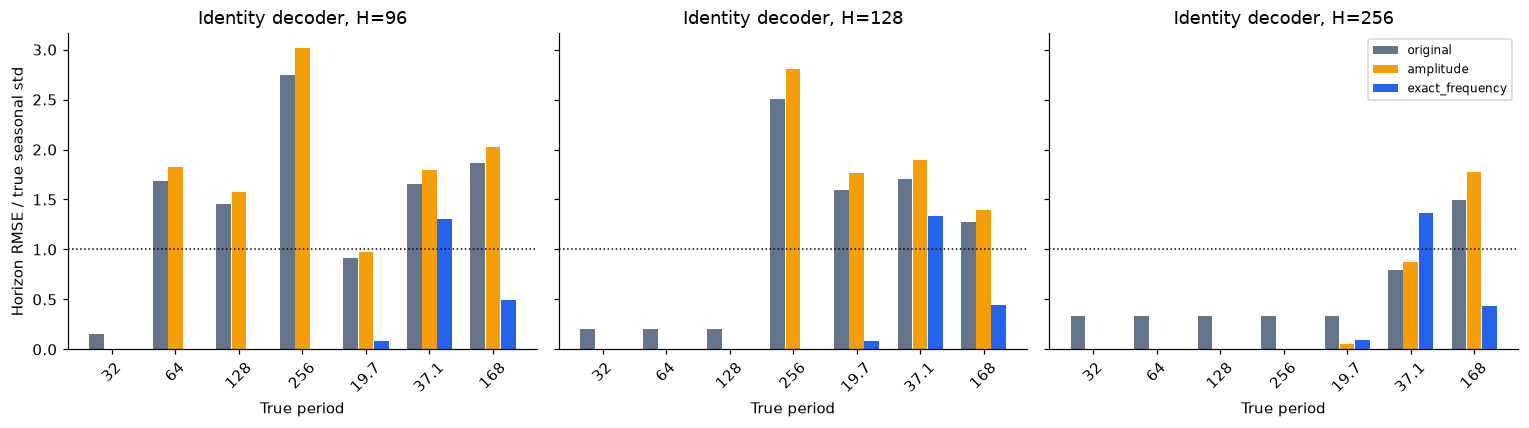

In [3]:
display(identity[identity.period.isin([32, 64, 128, 256])].pivot_table(
    index=['horizon', 'period'], columns='variant', values='nrmse_horizon').round(4))
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
periods = [32., 64., 128., 256., 19.7, 37.1, 168.]
for ax, horizon in zip(axes, [96, 128, 256]):
    for offset, variant in enumerate(variants):
        values = identity[(identity.horizon == horizon) & (identity.variant == variant)].set_index('period')
        ax.bar(np.arange(len(periods)) + (offset-1)*.24, values.loc[periods, 'nrmse_horizon'],
               width=.23, label=variant, color=colors[variant])
    ax.set_xticks(np.arange(len(periods)), [str(p).removesuffix('.0') for p in periods], rotation=45)
    ax.set_title(f'Identity decoder, H={horizon}')
    ax.axhline(1, color='black', linestyle=':', linewidth=1)
    ax.set_xlabel('True period')
axes[0].set_ylabel('Horizon RMSE / true seasonal std')
axes[-1].legend(fontsize=8)
fig.tight_layout()
plt.show()


## Forecast after training

Base test from 45 scenarios. Bars show the mean across three training seeds;
error bars show the standard deviation across seeds, not confidence intervals.
Lower CRPS is better; nominal coverage is 90%.


,horizon,variant,ncrps_mean,ncrps_std,nrmse_mean,coverage90_mean,seasonal_hor_nrmse_mean,seasonal_gain_mean
1,96,amplitude,0.32186,0.00080,0.55318,0.89788,0.62892,0.13786
14,96,exact_frequency,0.32784,0.00156,0.56288,0.90558,0.69188,0.09823
27,96,original,0.31994,0.00270,0.55020,0.90320,0.62820,0.14351
40,128,amplitude,0.33490,0.00738,0.57103,0.90198,0.66521,0.02239
53,128,exact_frequency,0.34044,0.00866,0.58237,0.89378,0.69129,0.09393
66,128,original,0.33286,0.00750,0.56840,0.89907,0.66888,0.02564
79,256,amplitude,0.36173,0.00962,0.61076,0.90054,0.65720,0.05729
92,256,exact_frequency,0.38142,0.01671,0.64251,0.89221,0.70524,0.09881
105,256,original,0.36098,0.00338,0.61053,0.90296,0.65536,0.05365


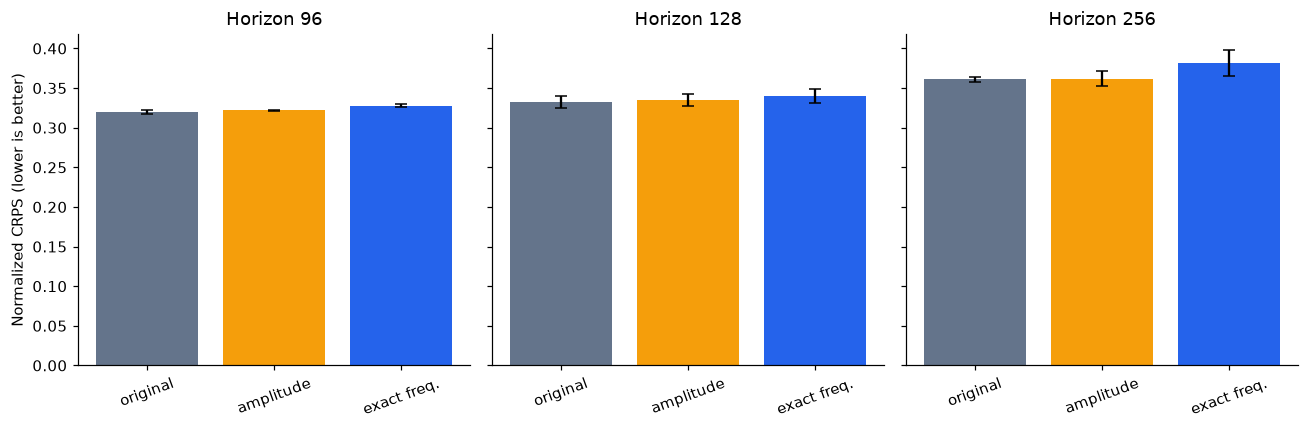

In [4]:
base = summary[summary.case == 'base']
display(base[['horizon', 'variant', 'ncrps_mean', 'ncrps_std', 'nrmse_mean',
              'coverage90_mean', 'seasonal_hor_nrmse_mean', 'seasonal_gain_mean']].round(5))
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, horizon in zip(axes, [96, 128, 256]):
    table = base[base.horizon == horizon].set_index('variant').loc[variants]
    ax.bar(range(3), table.ncrps_mean, yerr=table.ncrps_std, capsize=4,
           color=[colors[v] for v in variants])
    ax.set_xticks(range(3), ['original', 'amplitude', 'exact freq.'], rotation=20)
    ax.set_title(f'Horizon {horizon}')
axes[0].set_ylabel('Normalized CRPS (lower is better)')
fig.tight_layout()
plt.show()


## Paired comparisons and diagnostic cases

Δ = new variant − original: a negative value indicates improvement.
95% intervals use 2000 paired bootstrap resamples of test series **within each seed**.
They describe variation across test series, not uncertainty across new training seeds.
The diagnostic checks are exploratory; no correction for multiple comparisons was applied.


,horizon,seed,variant,delta,ci_low,ci_high,improvement_pct
6,96,0,amplitude,0.001813,-0.000359,0.003798,-0.565817
9,96,0,exact_frequency,0.007732,0.004308,0.010793,-2.413649
84,96,1,amplitude,0.003886,0.002011,0.006305,-1.225786
87,96,1,exact_frequency,0.009111,0.006713,0.011679,-2.873420
162,96,2,amplitude,0.000038,-0.001511,0.001713,-0.011676
165,96,2,exact_frequency,0.006861,0.004540,0.009364,-2.127938
240,128,0,amplitude,0.001239,0.000034,0.002534,-0.368166
243,128,0,exact_frequency,0.009083,0.007044,0.011241,-2.698189
318,128,1,amplitude,0.002276,0.000199,0.004517,-0.701934
321,128,1,exact_frequency,0.006222,0.003424,0.009025,-1.919152


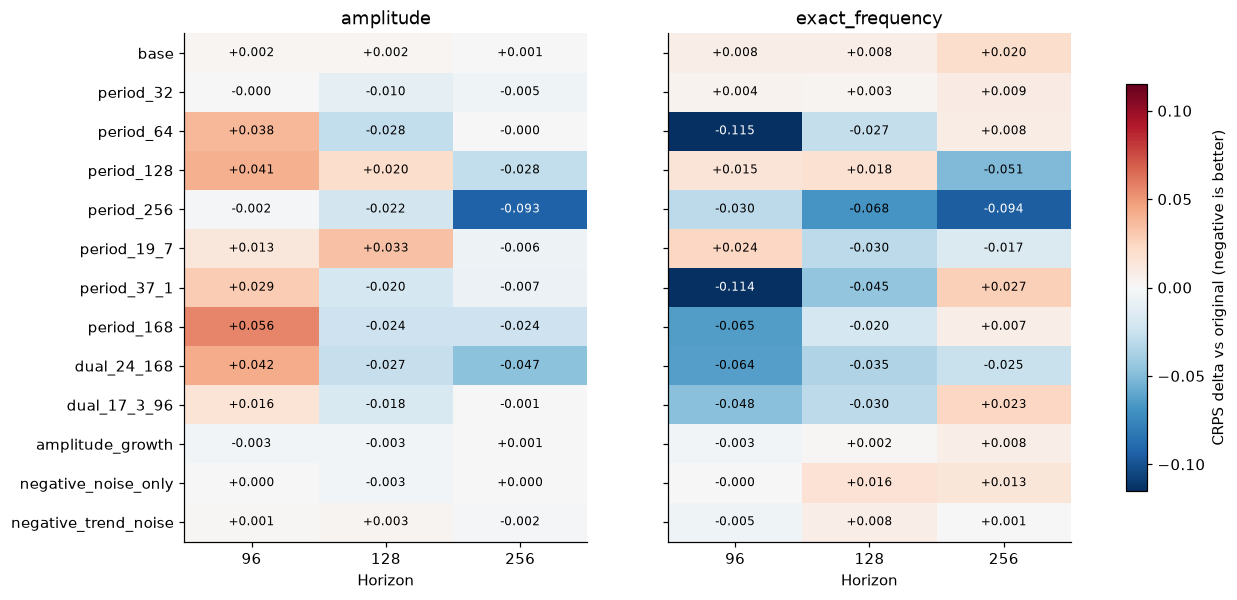

In [5]:
paired_base = paired[(paired.case == 'base') & (paired.metric == 'ncrps')]
display(paired_base[['horizon', 'seed', 'variant', 'delta', 'ci_low', 'ci_high', 'improvement_pct']].round(6))
effects = paired[paired.metric == 'ncrps'].groupby(['horizon', 'variant', 'case']).delta.mean()
cases = ['base', 'period_32', 'period_64', 'period_128', 'period_256', 'period_19_7',
         'period_37_1', 'period_168', 'dual_24_168', 'dual_17_3_96',
         'amplitude_growth', 'negative_noise_only', 'negative_trend_noise']
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
limit = max(abs(effects.min()), abs(effects.max()), 1e-6)
for ax, variant in zip(axes, ['amplitude', 'exact_frequency']):
    matrix = np.array([[effects.loc[(h, variant, c)] for h in [96, 128, 256]] for c in cases])
    im = ax.imshow(matrix, cmap='RdBu_r', vmin=-limit, vmax=limit, aspect='auto')
    for i in range(len(cases)):
        for j in range(3):
            ax.text(j, i, f'{matrix[i,j]:+.3f}', ha='center', va='center', fontsize=8,
                    color='white' if abs(matrix[i,j]) > .65*limit else 'black')
    ax.set_xticks(range(3), [96, 128, 256]); ax.set_yticks(range(len(cases)), cases)
    ax.set_title(variant); ax.set_xlabel('Horizon')
fig.colorbar(im, ax=axes, label='CRPS delta vs original (negative is better)', shrink=.8)
plt.show()


## Seasonal branch usage

`seasonal_gain` is the projection of the decoded seasonal component onto the true seasonal component in the context
(expected to be close to 1 for accurate recovery). Gain is undefined for series without seasonality.
`input_leak_abs` is the absolute projection of the input trend error onto the true seasonal component.
These coefficients are not energy fractions. Component error accounts for amplitude, phase, and shape.
We also measure the fraction of true seasonal energy in the FFT bins selected by
the seasonal encoder from the standard MA residual. Ground truth is used only for this diagnostic,
not as model input. A small value means that the relevant frequencies were missed by top-K selection.


,horizon,variant,input_leak_abs_mean,input_seasonal_nrmse_mean,seasonal_gain_mean,seasonal_share_mean,seasonal_hor_nrmse_mean
1,96,amplitude,0.78986,0.63411,0.13786,0.10426,0.62892
14,96,exact_frequency,0.81117,0.64737,0.09823,0.07633,0.69188
27,96,original,0.78755,0.63265,0.14351,0.11145,0.62820
40,128,amplitude,0.80551,0.64400,0.02239,0.01291,0.66521
53,128,exact_frequency,0.81116,0.64739,0.09393,0.06829,0.69129
66,128,original,0.80715,0.64503,0.02564,0.01621,0.66888
79,256,amplitude,0.80193,0.64166,0.05729,0.04178,0.65720
92,256,exact_frequency,0.80818,0.64559,0.09881,0.07793,0.70524
105,256,original,0.80031,0.64079,0.05365,0.03877,0.65536


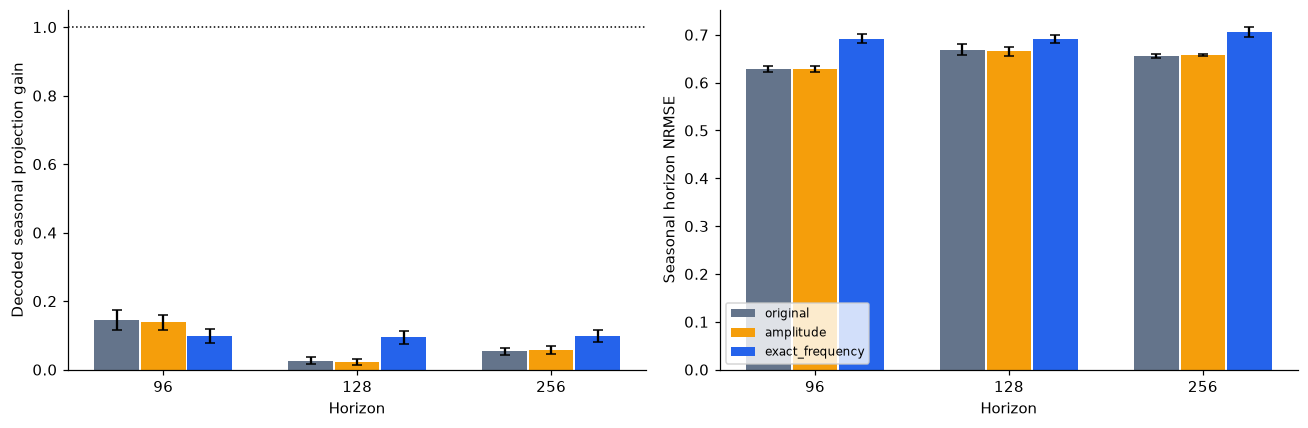

In [6]:
display(base[['horizon', 'variant', 'input_leak_abs_mean', 'input_seasonal_nrmse_mean',
              'seasonal_gain_mean', 'seasonal_share_mean', 'seasonal_hor_nrmse_mean']].round(5))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, label in zip(axes, ['seasonal_gain', 'seasonal_hor_nrmse'],
                            ['Decoded seasonal projection gain', 'Seasonal horizon NRMSE']):
    for offset, variant in enumerate(variants):
        table = base[base.variant == variant].set_index('horizon').loc[[96, 128, 256]]
        ax.bar(np.arange(3)+(offset-1)*.24, table[metric+'_mean'], width=.23,
               yerr=table[metric+'_std'], capsize=3, label=variant, color=colors[variant])
    ax.set_xticks(range(3), [96, 128, 256]); ax.set_xlabel('Horizon'); ax.set_ylabel(label)
axes[0].axhline(1, color='black', linestyle=':', linewidth=1)
axes[-1].legend(fontsize=8)
fig.tight_layout()
plt.show()


In [7]:
retention = topk.groupby(['horizon', 'variant', 'case']).topk_true_seasonal_energy.mean()
display(retention.unstack('case')[['base', 'period_32', 'period_64', 'period_128', 'period_256']].round(4))
trend_leak = topk.groupby(['horizon', 'variant', 'case']).decoded_trend_seasonal_gain.mean()
print('Projection of decoded trend error onto true seasonal (ideal: zero):')
display(trend_leak.unstack('case')[['base', 'period_32', 'period_64', 'period_128', 'period_256']].round(4))


Projection of decoded trend error onto true seasonal (ideal: zero):


case                       base  period_32  period_64  period_128  period_256
horizon variant                                                              
96      amplitude        0.5337     0.9583     0.0104         0.0         0.0
        exact_frequency  0.4844     0.8646     0.0000         0.0         0.0
        original         0.5358     0.9688     0.0104         0.0         0.0
128     amplitude        0.4954     0.8854     0.0000         0.0         0.0
        exact_frequency  0.4843     0.8750     0.0000         0.0         0.0
        original         0.4915     0.8854     0.0000         0.0         0.0
256     amplitude        0.5058     0.9271     0.0000         0.0         0.0
        exact_frequency  0.4918     0.8750     0.0000         0.0         0.0
        original         0.5107     0.9271     0.0000         0.0         0.0

case                       base  period_32  period_64  period_128  period_256
horizon variant                                                              
96      amplitude        0.8616     0.9619     1.0034      1.0166      1.0243
        exact_frequency  0.9041     0.9860     1.0117      1.0180      1.0281
        original         0.8499     0.9564     0.9962      1.0080      1.0174
128     amplitude        0.9885     1.0230     1.0282      1.0306      1.0342
        exact_frequency  0.8981     0.9690     0.9932      0.9994      1.0063
        original         0.9694     0.9952     0.9986      1.0016      1.0059
256     amplitude        0.9307     0.9857     0.9915      0.9937      0.9976
        exact_frequency  0.8808     0.9529     0.9756      0.9804      0.9834
        original         0.9324     0.9966     0.9973      0.9974      0.9995

## Example after training: period 64, seed 0, horizon 96

The first series of a diagnostic case selected in advance, rather than an example with the largest improvement.
Forecast and component means use 128 latent draws from the best validation checkpoint.
Checkpoint files and full predictions are stored in the Git-ignored runs folder.


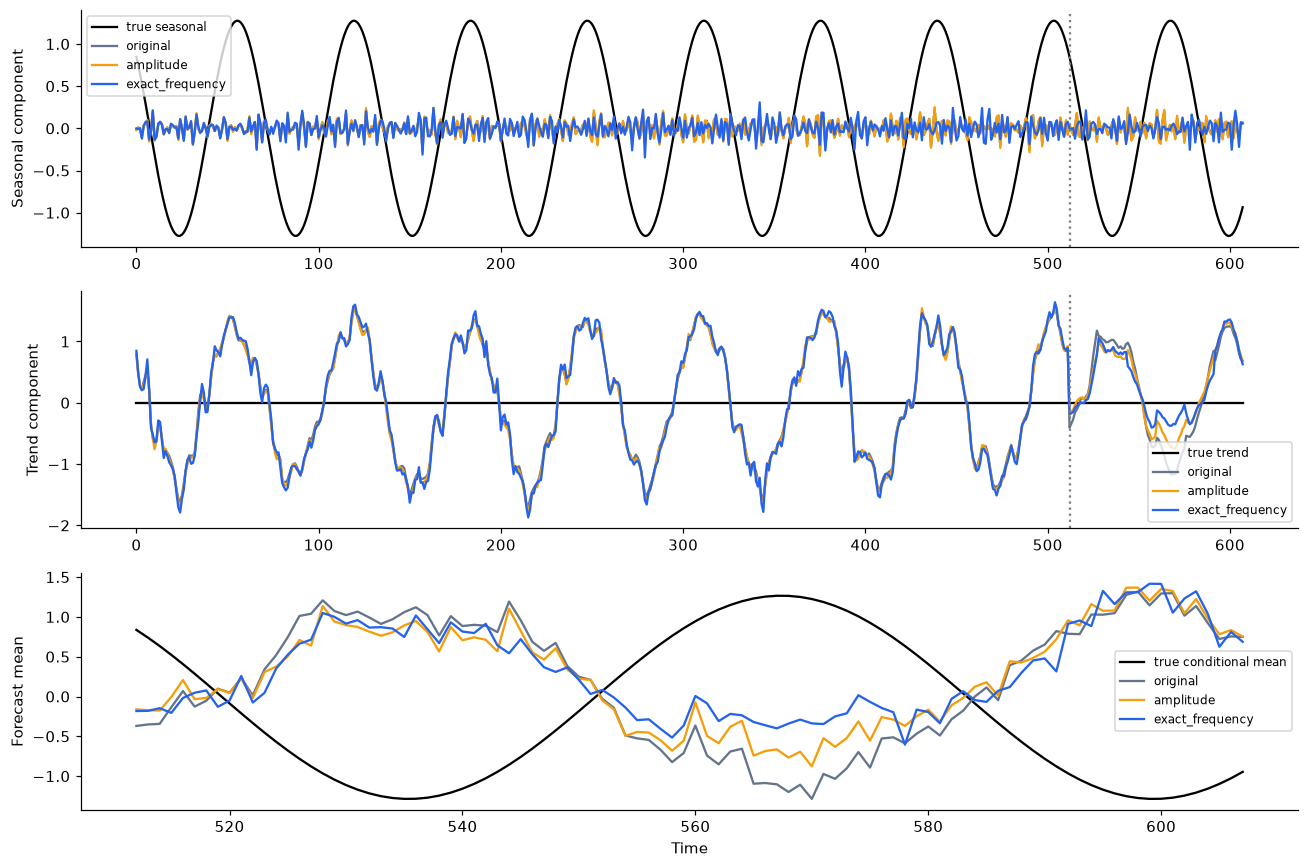

In [8]:
run_root = Path('/Users/andrew/Desktop/skoltech/DecoVAE_fm_project/experiments/decomposition/runs/fft_reconstruction_full')
# When reproducing elsewhere, run train.py with the default run id, or set DECOVAE_RUNS.
if not run_root.exists():
    import os
    run_root = Path(os.environ.get('DECOVAE_RUNS', EXP / 'runs')) / 'fft_reconstruction_full'
if (run_root / 'test.npz').exists():
    raw = dict(np.load(run_root / 'test.npz'))
    row = int(np.flatnonzero(raw['case'] == 'period_64')[0])
    horizon = 96
    t = np.arange(512+horizon)
    gt_seas = raw['seasonal'][row, :512+horizon] / raw['scale'][row, 0]
    gt_trend = (raw['trend'][row, :512+horizon] - raw['mean'][row, 0]) / raw['scale'][row, 0]
    mean = (raw['trend'][row, :512+horizon] + raw['seasonal'][row, :512+horizon]
            - raw['mean'][row, 0]) / raw['scale'][row, 0]
    fig, axes = plt.subplots(3, 1, figsize=(12, 8))
    axes[0].plot(t, gt_seas, color='black', label='true seasonal', linewidth=1.5)
    axes[1].plot(t, gt_trend, color='black', label='true trend', linewidth=1.5)
    axes[2].plot(t[512:], mean[512:], color='black', label='true conditional mean', linewidth=1.5)
    for variant in variants:
        predictions = dict(np.load(run_root / f'h96_s0_{variant}' / 'predictions.npz'))
        axes[0].plot(t, predictions['seasonal'][row], label=variant, color=colors[variant])
        axes[1].plot(t, predictions['trend'][row], label=variant, color=colors[variant])
        axes[2].plot(t[512:], predictions['mean'][row], label=variant, color=colors[variant])
    axes[0].axvline(512, color='gray', linestyle=':')
    axes[1].axvline(512, color='gray', linestyle=':')
    axes[0].set_ylabel('Seasonal component'); axes[1].set_ylabel('Trend component')
    axes[2].set_ylabel('Forecast mean')
    for ax in axes: ax.legend(fontsize=8)
    axes[2].set_xlabel('Time'); fig.tight_layout(); plt.show()
else:
    print('Raw run outputs absent; figures above and saved notebook outputs remain available.')


# FFT-only reconstruction ablation

Completed: 27 runs, 3 variants × 3 horizons (96/128/256) × 3 training seeds (0/1/2), 30 epochs each.
Native DecoVAEFM; only `_reconstruct_time_from_freq_tokens` differs. Original MA, learned encoders,
trend/seasonal/variance heads, noise latent and unchanged `benchmark.runner.loss` are shared.
All pairs have identical initial parameter hashes and batch orders. The learned MA weights remain trainable.

## Base test: mean ± SD over training seeds

CRPS and NRMSE are in context-standardized units; lower is better. SD is not a confidence interval.

| H | Variant | CRPS | Forecast NRMSE | Coverage90 | Seasonal horizon NRMSE | Seasonal gain (context) |
|---|---|---|---|---|---|---|
| 96 | original | 0.31994 ± 0.00270 | 0.55020 | 0.9032 | 0.62820 | 0.14351 |
| 96 | amplitude | 0.32186 ± 0.00080 | 0.55318 | 0.8979 | 0.62892 | 0.13786 |
| 96 | exact_frequency | 0.32784 ± 0.00156 | 0.56288 | 0.9056 | 0.69188 | 0.09823 |
| 128 | original | 0.33286 ± 0.00750 | 0.56840 | 0.8991 | 0.66888 | 0.02564 |
| 128 | amplitude | 0.33490 ± 0.00738 | 0.57103 | 0.9020 | 0.66521 | 0.02239 |
| 128 | exact_frequency | 0.34044 ± 0.00866 | 0.58237 | 0.8938 | 0.69129 | 0.09393 |
| 256 | original | 0.36098 ± 0.00338 | 0.61053 | 0.9030 | 0.65536 | 0.05365 |
| 256 | amplitude | 0.36173 ± 0.00962 | 0.61076 | 0.9005 | 0.65720 | 0.05729 |
| 256 | exact_frequency | 0.38142 ± 0.01671 | 0.64251 | 0.8922 | 0.70524 | 0.09881 |

## Paired forecast CRPS differences

Delta = corrected − original. Negative is better. Intervals are paired row-bootstrap (2000 resamples)
inside a training seed; they do not quantify uncertainty over future training seeds.

| H | Variant | Mean delta over seeds | Improved seeds | Seeds with CI entirely below zero |
|---|---|---|---|---|
| 96 | amplitude | +0.001912 | 0/3 | 0/3 |
| 96 | exact_frequency | +0.007901 | 0/3 | 0/3 |
| 128 | amplitude | +0.002044 | 0/3 | 0/3 |
| 128 | exact_frequency | +0.007580 | 0/3 | 0/3 |
| 256 | amplitude | +0.000749 | 2/3 | 1/3 |
| 256 | exact_frequency | +0.020446 | 0/3 | 0/3 |

## Observed results

- `amplitude`: base-test improvement with a bootstrap interval entirely below zero in at least 2/3 seeds at horizons: none.
  Diagnostic case × horizon pairs worse in all three seeds: 3 / 36 (exploratory signs, not multiplicity-corrected significance).
- `exact_frequency`: base-test improvement with a bootstrap interval entirely below zero in at least 2/3 seeds at horizons: none.
  Diagnostic case × horizon pairs worse in all three seeds: 6 / 36 (exploratory signs, not multiplicity-corrected significance).
- Average decoded seasonal projection gains on the base test range from 0.0224 to 0.1435; an exact component match would have gain 1.
  None of these decoder-only variants restores full seasonal component recovery on this training profile.
- `period_64`: mean fraction of true seasonal FFT variance retained in the encoder's top-K bins is 0.0023; decoded trend's seasonal projection gain is 0.9995 (ideal zero), averaged over this grid.
- `period_128`: mean fraction of true seasonal FFT variance retained in the encoder's top-K bins is 0.0000; decoded trend's seasonal projection gain is 1.0051 (ideal zero), averaged over this grid.
- `period_256`: mean fraction of true seasonal FFT variance retained in the encoder's top-K bins is 0.0000; decoded trend's seasonal projection gain is 1.0107 (ideal zero), averaged over this grid.
- In the trained original H96/seed0 checkpoint, scaling the final complex-linear seasonal head by 512/608 compensates amplitude-only reconstruction: maximum output difference 2.38e-07 on eight fixed test contexts with paired latent draws.

## Interpretation and scope

- The identity check confirms the amplitude convention and bin-rounding defects without training.
  Exact-frequency evaluation reconstructs periods dividing T=512 up to numerical precision.
- Exact-frequency evaluation is a T-periodic extension of the same top-K bins, not a true-period estimator.
  Off-grid seasonality can still extrapolate poorly. A decoder-only fix does not remove this limitation.
  In particular, the base positive periods 12/24/48/96 do not divide 512. The exact-k/T decoder forces
  seasonal(t+512)=seasonal(t), which the true seasonal does not satisfy; the trend head can compensate
  in the total mean, but this does not restore true component recovery.
- For a fixed horizon, amplitude-only correction is a constant rescaling which the learned seasonal head
  can absorb. The identity error is real, but a forecast improvement after training is not guaranteed.
- Trained performance and component recovery must be assessed separately using the table above and diagnostics.
  An operator defect does not by itself establish that correcting it fixes learned decomposition.
- Per-case diagnostics, paired intervals and three horizon segments are in results/fft_reconstruction_*.csv.
  Diagnostic comparisons are exploratory and have no multiple-comparison correction.

## Reproduction and limitations

2048 train / 256 validation / 512 base test + 12 × 32 held-out diagnostic series. Linear context-only
normalization, AdamW 0.001, batch32, clip1. Best validation-CRPS checkpoint from a fixed 30-epoch budget;
32 validation and 128 test latent + observation draws. No test metric is used to select checkpoints.
Same underlying paths are sliced for all horizons. Series seeds: 719 / 100719 / 200719.
Synthetic data only; three training seeds; this is not the larger existing `night` benchmark.
Each horizon is trained separately. Generalization of one trained model to an unseen horizon is not tested.
Local runtime: Python 3.13.5, torch 2.8.0, CPU; differs from uv.lock.
Provenance, data hashes, source snapshots, checkpoints, histories and per-series outputs are under
`runs/fft_reconstruction_full/` (Git-ignored). Summaries and the executed notebook are tracked artifacts.
